# Chapter 3 — Score-Based Perspective: From EBMs to NCSN

This notebook follows Chapter 3 of *The Principles of Diffusion Models*. We move from the
**variational view** (Ch. 2: VAE → DDPM) to the **score-based view**: Energy-Based Models (EBMs)
→ score matching → denoising score matching (DSM) → Noise Conditional Score Networks (NCSN).

**Roadmap**
1. Energy-Based Models and why the partition function is the whole problem
2. The score function `s(x) = ∇x log p(x)` as a way to sidestep that problem
3. Vanilla (implicit) score matching + Langevin dynamics — and why it struggles
4. Denoising score matching (DSM) — a tractable, single-noise-level fix
5. NCSN — multiple noise levels + annealed Langevin dynamics
6. Comparing NCSN and DDPM side by side

All experiments use a 2D toy dataset (two moons) so we can *see* the score field and the sampling
trajectories directly — this is exactly the recommended approach before touching image data.


In [1]:
# --- Setup -------------------------------------------------------------
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## 1. Energy-Based Models (EBMs)

An EBM defines a density through an **energy function** $E_\phi(x)$ that is *low* on data and
*high* everywhere else:

$$p_\phi(x) = \frac{\exp(-E_\phi(x))}{Z_\phi}, \qquad Z_\phi = \int \exp(-E_\phi(x))\,dx.$$

$Z_\phi$ (the partition function) is what makes EBMs hard: it's an integral over all of $\mathbb{R}^D$,
generally intractable, yet required for maximum-likelihood training since

$$\mathcal{L}_{\text{MLE}}(\phi) = -\,\mathbb{E}_{p_{\text{data}}}[E_\phi(x)] \;-\; \log Z_\phi.$$

The first term is easy (just lower the energy of real data). The second term — the log partition
function — needs samples from the model itself, which is expensive (MCMC, contrastive divergence, ...).

**Key escape hatch — the score.** Define the score function

$$s(x) := \nabla_x \log p(x).$$

Because $\log p_\phi(x) = -E_\phi(x) - \log Z_\phi$ and $Z_\phi$ does not depend on $x$:

$$\nabla_x \log p_\phi(x) = -\nabla_x E_\phi(x).$$

The partition function's gradient is exactly zero — **the score never sees $Z_\phi$.** This is the
whole motivation of this chapter: if we can train a network to match the *score* rather than the
*density*, we never need to touch $Z_\phi$ at all. Sampling then proceeds via **Langevin dynamics**,
which only needs the score to walk samples uphill in log-density:

$$\tilde{x}_{n+1} = \tilde{x}_n + \eta\, s(\tilde{x}_n) + \sqrt{2\eta}\,\epsilon_n, \qquad \epsilon_n \sim \mathcal{N}(0, I).$$


## 2. Score-Based Models - Training with (Explicit) Score Matching

We directly parameterize the score as a vector field $s_\phi(x) \approx \nabla_x \log p_{\text{data}}(x)$
and would like to fit it by minimizing

$$\mathcal{L}_{\text{SM}}(\phi) = \tfrac12\,\mathbb{E}_{x\sim p_{\text{data}}}\big[\|s_\phi(x) - s(x)\|_2^2\big].$$

Problem: the target $s(x)$ is unknown. **Hyvärinen's trick** (integration by parts) rewrites this,
up to an additive constant that doesn't depend on $\phi$, as a *tractable* objective that only needs
samples and the model itself:

$$\tilde{\mathcal{L}}_{\text{SM}}(\phi) = \mathbb{E}_{x\sim p_{\text{data}}}\Big[-\operatorname{Tr}\big(\nabla^2_x s_\phi(x)\big) + \tfrac12\|s_\phi(x)\|_2^2\Big].$$

The trace term is the trace of the Jacobian of the score network — i.e. it requires
second-order information (how the score itself changes with $x$). For our toy 2D data this is cheap
to compute exactly with autograd; in high dimensions it is why people later prefer *denoising* score
matching instead (Section 3).


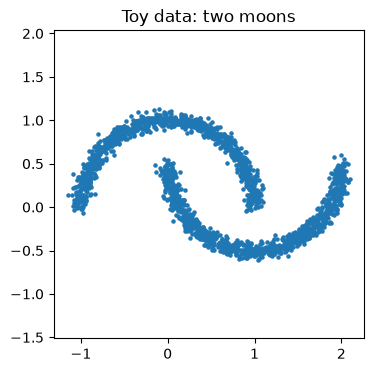

In [2]:
# --- Toy dataset: two moons ---------------------------------------------
def sample_data(n):
    x, _ = make_moons(n_samples=n, noise=0.05)
    return torch.tensor(x, dtype=torch.float32)

data = sample_data(2000)
plt.figure(figsize=(4, 4))
plt.scatter(data[:, 0], data[:, 1], s=5)
plt.title("Toy data: two moons")
plt.axis("equal")
plt.show()

In [3]:
# --- Score network: a small MLP mapping x -> R^D (same dim as x) --------
class ScoreNet(nn.Module):
    # Plain MLP score network s_phi(x) for 2D toy data (no noise-conditioning yet).
    def __init__(self, dim=2, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, dim),
        )
    def forward(self, x):
        return self.net(x)


def exact_trace_jacobian(score_net, x):
    # Tr(grad_x s_phi(x)) computed exactly (cheap since D=2 for toy data).
    # For each output coordinate i, take d(s_i)/dx_i and sum over i.
    x = x.requires_grad_(True)
    s = score_net(x)
    trace = 0.0
    for i in range(x.shape[1]):
        grad_i = torch.autograd.grad(s[:, i].sum(), x, create_graph=True)[0][:, i]
        trace = trace + grad_i
    return trace, s


def train_vanilla_sm(score_net, data, n_steps=3000, batch_size=256, lr=1e-3):
    # Minimize Hyvarinen's tractable score-matching objective:
    # Tr(grad_x s_phi(x)) + 1/2 ||s_phi(x)||^2  (no partition function needed!)
    opt = torch.optim.Adam(score_net.parameters(), lr=lr)
    for step in range(n_steps):
        idx = torch.randint(0, len(data), (batch_size,))
        x = data[idx].to(device)
        trace, s = exact_trace_jacobian(score_net, x)
        loss = (trace + 0.5 * (s ** 2).sum(dim=1)).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 1000 == 0:
            print(f"[vanilla SM] step {step:5d}  loss {loss.item():.4f}")
    return score_net

score_net_vanilla = ScoreNet().to(device)
score_net_vanilla = train_vanilla_sm(score_net_vanilla, data)

[vanilla SM] step     0  loss -0.0287
[vanilla SM] step  1000  loss -157.0323
[vanilla SM] step  2000  loss -177.3607


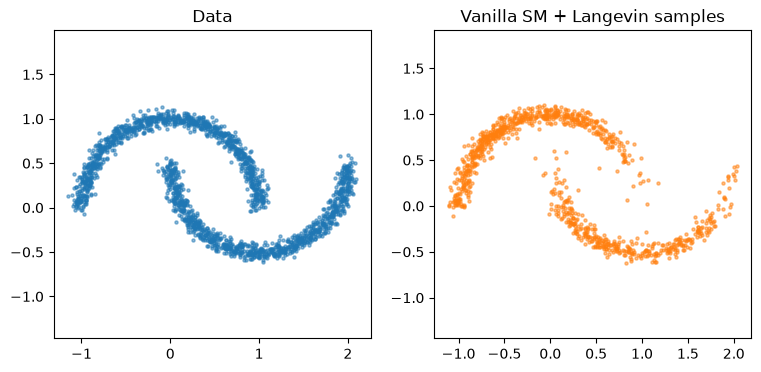

In [4]:
# --- Langevin dynamics sampler (generic: works with any callable score fn) ---
@torch.no_grad()
def langevin_sample(score_fn, n_samples=1000, dim=2, n_steps=1000, step_size=5e-4):
    # x_{n+1} = x_n + eta * s(x_n) + sqrt(2 eta) * noise
    x = torch.randn(n_samples, dim, device=device)
    for _ in range(n_steps):
        noise = torch.randn_like(x)
        x = x + step_size * score_fn(x) + (2 * step_size) ** 0.5 * noise
    return x.cpu()

samples_vanilla = langevin_sample(score_net_vanilla, n_steps=1000, step_size=5e-4)

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].scatter(data[:, 0], data[:, 1], s=5, alpha=0.5)
ax[0].set_title("Data")
ax[1].scatter(samples_vanilla[:, 0], samples_vanilla[:, 1], s=5, alpha=0.5, color="tab:orange")
ax[1].set_title("Vanilla SM + Langevin samples")
for a in ax: a.axis("equal")
plt.show()

**What to notice:** vanilla score matching tends to produce noisy/incomplete coverage of the two
moons — the score estimate is unreliable in **low-density regions** (there's little data there to
constrain it), and Langevin dynamics needs a *good* score everywhere it walks through, including the
sparse regions between/around the modes. This is the problem NCSN is built to fix (Section 4).


## 3. Denoising Score Matching (DSM)

Instead of trying to match the score of the raw (spiky, low-coverage) data distribution, **perturb**
the data with a small amount of Gaussian noise and match the score of the *smoothed* distribution
instead. This has two benefits: (a) the noised distribution has full support everywhere, so the score
target is well-defined even far from the original data, and (b) the regression target becomes
**closed-form**, so no second derivatives are needed at all.

Let $\tilde{x} = x + \sigma \epsilon,\ \epsilon\sim\mathcal N(0,I)$, so the perturbation kernel is
$p_\sigma(\tilde x \mid x) = \mathcal N(\tilde x; x, \sigma^2 I)$. Its score has a closed form:

$$\nabla_{\tilde x}\log p_\sigma(\tilde x \mid x) = \frac{x - \tilde x}{\sigma^2}.$$

Vincent's theorem says that matching this *conditional* score is (up to a constant) equivalent to
matching the score of the true marginal $p_\sigma(\tilde x)$. The **DSM objective**:

$$\mathcal{L}_{\text{DSM}}(\phi;\sigma) = \tfrac12\,\mathbb{E}_{x,\epsilon}\Big[\big\|\,s_\phi(x+\sigma\epsilon;\sigma) + \tfrac{\epsilon}{\sigma}\,\big\|_2^2\Big].$$

This is just a **regression problem**: predict $-\epsilon/\sigma$ from the noisy input. No Jacobian
trace, no partition function — purely a supervised MSE loss.


In [5]:
# --- Denoising Score Matching at a single, small noise level -------------
SIGMA_DSM = 0.05  # a single, fixed noise level

def train_dsm(score_net, data, sigma, n_steps=5000, batch_size=256, lr=1e-3):
    # Regression objective: predict -eps/sigma from the noised sample x + sigma*eps
    opt = torch.optim.Adam(score_net.parameters(), lr=lr)
    for step in range(n_steps):
        idx = torch.randint(0, len(data), (batch_size,))
        x = data[idx].to(device)
        eps = torch.randn_like(x)
        x_noisy = x + sigma * eps
        target = -eps / sigma                      # closed-form conditional score
        pred = score_net(x_noisy)
        loss = ((pred - target) ** 2).sum(dim=1).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 1000 == 0:
            print(f"[DSM sigma={sigma}] step {step:5d}  loss {loss.item():.4f}")
    return score_net

score_net_dsm = ScoreNet().to(device)
score_net_dsm = train_dsm(score_net_dsm, data, SIGMA_DSM)


[DSM sigma=0.05] step     0  loss 875.3978
[DSM sigma=0.05] step  1000  loss 724.6896
[DSM sigma=0.05] step  2000  loss 672.4199
[DSM sigma=0.05] step  3000  loss 590.2010
[DSM sigma=0.05] step  4000  loss 592.4674


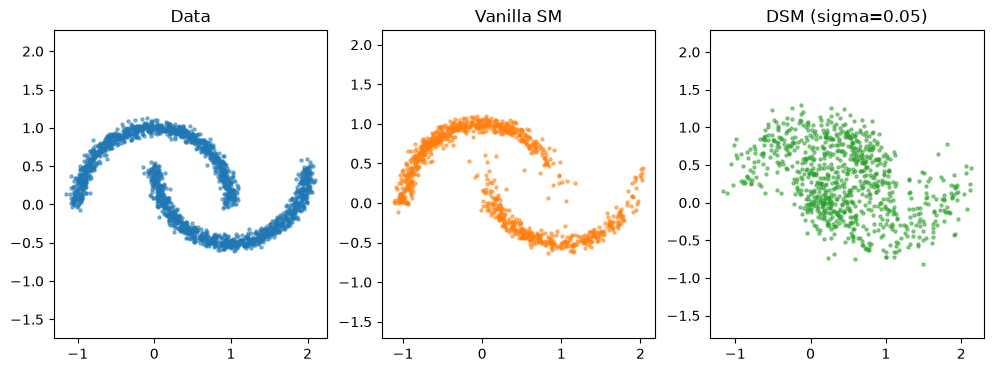

In [6]:
# --- Sample with Langevin dynamics using the DSM score --------------------
samples_dsm = langevin_sample(score_net_dsm, n_steps=1000, step_size=0.01)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].scatter(data[:, 0], data[:, 1], s=5, alpha=0.5)
ax[0].set_title("Data")
ax[1].scatter(samples_vanilla[:, 0], samples_vanilla[:, 1], s=5, alpha=0.5, color="tab:orange")
ax[1].set_title("Vanilla SM")
ax[2].scatter(samples_dsm[:, 0], samples_dsm[:, 1], s=5, alpha=0.5, color="tab:green")
ax[2].set_title(f"DSM (sigma={SIGMA_DSM})")
for a in ax: a.axis("equal")
plt.show()

**What to notice:** DSM is more *stable* to train (pure regression, no second derivatives) and
usually gives cleaner samples than vanilla SM. But there's still a fundamental tension baked into the
single fixed sigma:
- **too small** sigma → score estimate is accurate near the data, but Langevin still struggles to
  move *between* the two moons (vanishing gradients in the gap between modes).
- **too large** sigma → easy to sample from (no gaps left), but the noised distribution has lost
  the fine structure of the two moons, so samples are blurry/over-smoothed.

One noise level can't have it both ways. NCSN's fix: use **many** noise levels at once.


## 4. Noise Conditional Score Networks (NCSN)

Song & Ermon (2019) train a **single, noise-conditional** score network $s_\phi(x, \sigma)$ across a
whole ladder of noise levels $0 < \sigma_1 < \sigma_2 < \dots < \sigma_L$ ($\sigma_1$ small enough to
preserve detail, $\sigma_L$ large enough to smooth out the modes and make the space easy to explore).

**Training objective** — just DSM, summed over all levels with a per-level weight $\lambda(\sigma_i)$:

$$\mathcal{L}_{\text{NCSN}}(\phi) = \sum_{i=1}^L \lambda(\sigma_i)\, \mathcal{L}_{\text{DSM}}(\phi;\sigma_i),
\qquad
\mathcal{L}_{\text{DSM}}(\phi;\sigma) = \tfrac12\,\mathbb{E}\Big[\big\|s_\phi(\tilde x,\sigma) - \tfrac{x-\tilde x}{\sigma^2}\big\|_2^2\Big].$$

A common, convenient weighting is $\lambda(\sigma_i) = \sigma_i^2$, which puts all noise levels on a
comparable loss scale.

**Sampling — Annealed Langevin Dynamics.** Start from pure noise at the *largest* scale $\sigma_L$,
run a few Langevin steps there, then use that result to *initialize* Langevin at the next smaller
scale $\sigma_{L-1}$, and so on down to $\sigma_1 \approx 0$. Coarse structure is resolved first
(easy, smooth landscape); fine detail is resolved last (hard, but now well-initialized):

```
x ~ N(0, sigma_L^2 I)
for l = L, L-1, ..., 1:
    run K steps of Langevin dynamics at noise level sigma_l, using s_phi(., sigma_l)
    (each level's output initializes the next, smaller level)
return x   # approx. sample from p_data
```

The step size is typically scaled with the noise level, $\eta_\ell = \delta\cdot(\sigma_\ell/\sigma_1)^2$,
so early (coarse, high-noise) steps move further and later (fine, low-noise) steps move more gently.


In [7]:
# --- Noise-conditional score network --------------------------------------
class NCSN(nn.Module):
    # Score network conditioned on noise level sigma.
    # We feed log(sigma) alongside x -- a simple, effective conditioning for toy data
    # (image-scale NCSNs instead use conditional normalization layers).
    def __init__(self, dim=2, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim + 1, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, dim),
        )
    def forward(self, x, sigma):
        # sigma: scalar or (batch,) tensor -> broadcast as an extra input feature
        if sigma.dim() == 0:
            sigma = sigma.expand(x.shape[0])
        log_sigma = torch.log(sigma).unsqueeze(1)
        inp = torch.cat([x, log_sigma], dim=1)
        return self.net(inp)



In [8]:
# --- Geometric noise schedule (small to large), as recommended by Song & Ermon ---
L = 10
sigma_min, sigma_max = 0.02, 0.2
sigmas = torch.exp(torch.linspace(np.log(sigma_max), np.log(sigma_min), L)).to(device)
print("noise levels (sigma_L -> sigma_1):", [round(s.item(), 3) for s in sigmas])

noise levels (sigma_L -> sigma_1): [0.2, 0.155, 0.12, 0.093, 0.072, 0.056, 0.043, 0.033, 0.026, 0.02]


In [9]:
# --- Train NCSN: DSM loss averaged over all noise levels, per batch -------
def train_ncsn(model, data, sigmas, n_steps=5000, batch_size=256, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    L = len(sigmas)
    for step in range(n_steps):
        idx = torch.randint(0, len(data), (batch_size,))
        x = data[idx].to(device)
        # sample a random noise level per example (standard NCSN training trick)
        labels = torch.randint(0, L, (batch_size,), device=device)
        sigma_batch = sigmas[labels]
        eps = torch.randn_like(x)
        x_noisy = x + sigma_batch.unsqueeze(1) * eps
        target = -eps / sigma_batch.unsqueeze(1)          # closed-form conditional score
        pred = model(x_noisy, sigma_batch)
        # lambda(sigma) = sigma^2 weighting balances loss scale across noise levels
        weight = sigma_batch ** 2
        loss = (weight * ((pred - target) ** 2).sum(dim=1)).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 1000 == 0:
            print(f"[NCSN] step {step:5d}  loss {loss.item():.4f}")
    return model

ncsn = NCSN().to(device)
ncsn = train_ncsn(ncsn, data, sigmas, n_steps=10000)


[NCSN] step     0  loss 2.0830
[NCSN] step  1000  loss 1.8867
[NCSN] step  2000  loss 1.7113
[NCSN] step  3000  loss 1.5344
[NCSN] step  4000  loss 1.6678
[NCSN] step  5000  loss 1.4521
[NCSN] step  6000  loss 1.4361
[NCSN] step  7000  loss 1.4963
[NCSN] step  8000  loss 1.7066
[NCSN] step  9000  loss 1.4210


In [10]:
# --- Annealed Langevin dynamics sampler (Algorithm 1 in Ch. 3) ------------
@torch.no_grad()
def annealed_langevin_sample(model, sigmas, n_samples=1000, dim=2, n_steps_per_level=100, delta=5e-4):
    x = torch.randn(n_samples, dim, device=device) * sigmas[0]  # start ~ N(0, sigma_L^2 I)
    sigma_1 = sigmas[-1]
    for sigma in sigmas:
        eta = delta * (sigma / sigma_1) ** 2     # step size scaled by noise level
        for _ in range(n_steps_per_level):
            noise = torch.randn_like(x)
            score = model(x, sigma.expand(x.shape[0]))
            x = x + eta * score + (2 * eta) ** 0.5 * noise
        # output of this level initializes Langevin at the next (smaller) level
    return x.cpu()

samples_ncsn = annealed_langevin_sample(ncsn, sigmas, n_steps_per_level=100)


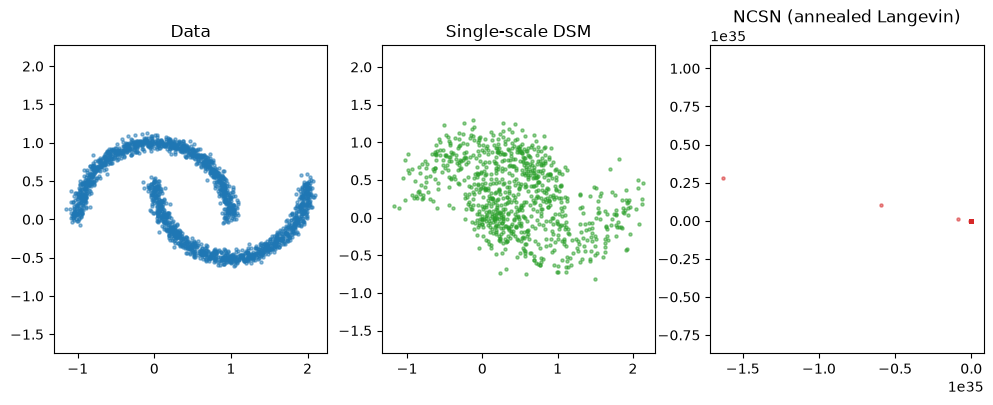

In [11]:
# --- Compare: data vs. single-scale DSM vs. NCSN (annealed) ---------------
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].scatter(data[:, 0], data[:, 1], s=5, alpha=0.5)
ax[0].set_title("Data")
ax[1].scatter(samples_dsm[:, 0], samples_dsm[:, 1], s=5, alpha=0.5, color="tab:green")
ax[1].set_title("Single-scale DSM")
ax[2].scatter(samples_ncsn[:, 0], samples_ncsn[:, 1], s=5, alpha=0.5, color="tab:red")
ax[2].set_title("NCSN (annealed Langevin)")
for a in ax: a.axis("equal")
plt.show()


**What to notice:** the annealed sampler should cover both moons more faithfully and with
sharper structure than the single-scale DSM sampler — the high-noise levels let it explore and find
both modes (no vanishing-gradient gap to get stuck in), while the low-noise levels at the end recover
fine detail. This coverage-vs-detail trade-off, solved by annealing, is precisely the point of NCSN.


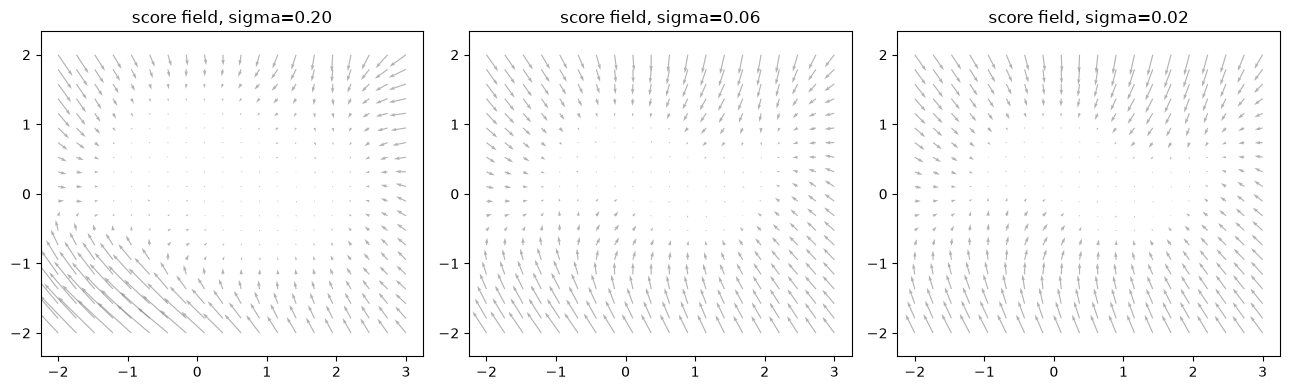

In [12]:
# --- Visualize the learned score field at a few noise levels --------------
def plot_score_field(model, sigma, ax, xlim=(-2, 3), ylim=(-2, 2), grid=20):
    xs = torch.linspace(*xlim, grid)
    ys = torch.linspace(*ylim, grid)
    X, Y = torch.meshgrid(xs, ys, indexing="xy")
    pts = torch.stack([X.flatten(), Y.flatten()], dim=1).to(device)
    with torch.no_grad():
        s = model(pts, torch.tensor(sigma, device=device).expand(pts.shape[0])).cpu()
    ax.quiver(pts[:, 0], pts[:, 1], s[:, 0], s[:, 1], color="gray", alpha=0.6)
    ax.set_title(f"score field, sigma={sigma:.2f}")
    ax.axis("equal")

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, sigma in zip(ax, [sigmas[0].item(), sigmas[L // 2].item(), sigmas[-1].item()]):
    plot_score_field(ncsn, sigma, a)
plt.tight_layout()
plt.show()


Notice how the field is smoother/coarser (points more uniformly toward the overall mass) at
large sigma, and sharper/more structured (clearly outlining the two moons) at small sigma — this
is the visual signature of what annealing exploits.


## 5. NCSN vs. DDPM — Side by Side

Both models perturb data with noise and learn to undo it, and it turns out their optimal targets are
**exact rescalings of each other** (via Tweedie's formula):

$$s^*(x_\sigma, \sigma) = -\frac{1}{\sigma}\,\mathbb{E}[\epsilon \mid x_\sigma] = -\frac{1}{\sigma}\,\epsilon^*(x_\sigma,\sigma).$$

So a perfectly trained DDPM noise-predictor and a perfectly trained NCSN score-predictor encode the
same information, just reparameterized.

| | **NCSN** | **DDPM** |
|---|---|---|
| Forward step | $x_{i+1}=x_i+\sqrt{\sigma_{i+1}^2-\sigma_i^2}\,\epsilon$ | $x_{i+1}=\sqrt{1-\beta_i}\,x_i+\sqrt{\beta_i}\,\epsilon$ |
| $x_i \mid x$ | $x_i = x + \sigma_i \epsilon$ | $x_i = \bar\alpha_i x + \sqrt{1-\bar\alpha_i^2}\,\epsilon$ |
| Prior | $\mathcal N(0,\sigma_L^2 I)$ | $\mathcal N(0, I)$ |
| Loss target | score $s_\phi(x_i,\sigma_i)\approx -\epsilon/\sigma_i$ | noise $\epsilon_\phi(x_i,i)\approx\epsilon$ |
| Sampling | Langevin at each level, annealed | ancestral sampling through $p_\phi(x_{i-1}\mid x_i)$ |

**Shared bottleneck.** Both need many discrete levels/steps (dense noise schedule) to work well,
which is why sampling from either is slow (hundreds–thousands of network evaluations). This shared
limitation is exactly what motivates the continuous-time **Score SDE** framework of Chapter 4, which
unifies NCSN and DDPM as two discretizations of the same underlying stochastic process.


## 6. Exercises / Checkpoint

1. Re-run vanilla score matching with a lower Langevin step size / more steps — does coverage of
   both moons improve, or does it just get slower without fixing the underlying issue?
2. Try DSM with a much larger sigma (e.g. 1.0) and a much smaller one (e.g. 0.05). Confirm the
   trade-off described above: large sigma -> easy sampling but blurred structure; small sigma ->
   sharp but Langevin struggles to jump between moons.
3. Reduce `L` (number of noise levels) in NCSN to 2 or 3 — how much does annealed sample quality
   degrade? This should give you intuition for why NCSN eventually motivates a *continuum* of noise
   levels (Chapter 4's Score SDE).
4. In your own words (before peeking back at Section 5's table): why must NCSN and DDPM samplers
   both be slow, given that they're mathematically equivalent at the level of the optimal score?

**Checkpoint:** you should be able to explain why single-noise-level score matching fails on
multimodal data, and why annealing across many noise levels fixes it.
